# Mesin Pencari Dokumen Berita Berbahasa Indonesia dengan BM25

In [4]:
import pandas as pd
import numpy as np
import re
import string
import math
import pickle
from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

tqdm.pandas()
print("library berhasil dimuat")

library berhasil dimuat


## 1. Preprocessing

In [5]:
df = pd.read_csv("../data/news_data.csv")

df_clean = df[["title", "article_text", "publish_date", "tag"]].copy()
df_clean.columns = ["title", "content", "date", "category"]
df_clean = df_clean.dropna(subset=["content"]).reset_index(drop=True)

# Opsional: ambil subset dulu supaya cepat waktu development
df_clean = df_clean.sample(n=10000, random_state=42).reset_index(drop=True)
df_clean["doc_id"] = df_clean.index

print("Jumlah dokumen:", len(df_clean))
df_clean.head()

Jumlah dokumen: 10000


,title,content,date,category,doc_id
0,Prabowo-Gibran Disalami Anies-Cak Imin Usai Pi...,"Pasangan capres-cawapres nomor 1, Anies Baswed...",2023-11-14 21:42:00+07:00,"['anies baswedan', 'muhaimin iskandar', 'prabo...",0
1,"Mobil F 414 RI ke Istana Bogor, SBY Dikabarkan...",Mobil berpelat F 414 RI yang biasa ditumpangi ...,2023-10-02 17:34:00+07:00,"['sby', 'jokowi', 'istana bogor', 'pilpres 202...",1
2,Geger Kepala Desa Dukung Prabowo-Gibran,Butuh waktu lama bagi Gibran Rakabuming Raka u...,2023-11-26 23:53:00+07:00,[' Spotlight '],2
3,"PDIP Sebut Gibran Pembangkang, Projo: Itu Hany...",Ketua DPP PDIP Ahmad Basarah menyebut Gibran R...,2023-10-29 07:54:00+07:00,"['gibran rakabuming', 'pdip', 'projo', 'pemilu...",3
4,Relawan Prabowo Akan Sebar Saksi Penuhi TPS di...,Ketua Dewan Pembina Gerakan Relawan Rakyat Pen...,2023-07-21 17:38:00+07:00,"['relawan prabowo', 'prabowo subianto', 'pilpr...",4


In [6]:
stemmer = StemmerFactory().create_stemmer()
stopword_list = set(StopWordRemoverFactory().get_stop_words())
stem_cache = {}

def case_folding(text):
    return text.lower()

def clean_text(text):
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    return text.split()

def remove_stopwords(tokens):
    return [w for w in tokens if w not in stopword_list]

def stem_tokens(tokens):
    result = []
    for w in tokens:
        if w not in stem_cache:
            stem_cache[w] = stemmer.stem(w)
        result.append(stem_cache[w])
    return result

def preprocess_text(text):
    text = case_folding(text)
    text = clean_text(text)
    tokens = tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = stem_tokens(tokens)
    return tokens

# Test cepat
print(preprocess_text("Pemerintah UMUMKAN Kebijakan Ekonomi BARU! Cek: https://detik.com"))

['perintah', 'umum', 'bijak', 'ekonomi', 'baru', 'cek']


In [7]:
df_clean["tokens"] = df_clean["content"].progress_apply(preprocess_text)

df_clean.to_pickle("../data/preprocessed_news.pkl")
print("Preprocessing selesai, data disimpan")
df_clean.head()

100%|██████████| 10000/10000 [55:44<00:00,  2.99it/s]  


Preprocessing selesai, data disimpan


,title,content,date,category,doc_id,tokens
0,Prabowo-Gibran Disalami Anies-Cak Imin Usai Pi...,"Pasangan capres-cawapres nomor 1, Anies Baswed...",2023-11-14 21:42:00+07:00,"['anies baswedan', 'muhaimin iskandar', 'prabo...",0,"[pasang, caprescawapres, nomor, anies, basweda..."
1,"Mobil F 414 RI ke Istana Bogor, SBY Dikabarkan...",Mobil berpelat F 414 RI yang biasa ditumpangi ...,2023-10-02 17:34:00+07:00,"['sby', 'jokowi', 'istana bogor', 'pilpres 202...",1,"[mobil, pelat, f, ri, biasa, tumpang, presiden..."
2,Geger Kepala Desa Dukung Prabowo-Gibran,Butuh waktu lama bagi Gibran Rakabuming Raka u...,2023-11-26 23:53:00+07:00,[' Spotlight '],2,"[butuh, waktu, lama, gibran, rakabuming, raka,..."
3,"PDIP Sebut Gibran Pembangkang, Projo: Itu Hany...",Ketua DPP PDIP Ahmad Basarah menyebut Gibran R...,2023-10-29 07:54:00+07:00,"['gibran rakabuming', 'pdip', 'projo', 'pemilu...",3,"[ketua, dpp, pdip, ahmad, basarah, sebut, gibr..."
4,Relawan Prabowo Akan Sebar Saksi Penuhi TPS di...,Ketua Dewan Pembina Gerakan Relawan Rakyat Pen...,2023-07-21 17:38:00+07:00,"['relawan prabowo', 'prabowo subianto', 'pilpr...",4,"[ketua, dewan, bina, gera, rawan, rakyat, duku..."


## 2. Indexing

In [8]:
inverted_index = defaultdict(set)   # kata -> set doc_id
tf = defaultdict(dict)              # doc_id -> {kata: jumlah kemunculan}
doc_length = {}                     # doc_id -> jumlah token

for _, row in tqdm(df_clean.iterrows(), total=len(df_clean)):
    doc_id = row["doc_id"]
    tokens = row["tokens"]
    doc_length[doc_id] = len(tokens)

    term_count = defaultdict(int)
    for term in tokens:
        term_count[term] += 1

    for term, count in term_count.items():
        tf[doc_id][term] = count
        inverted_index[term].add(doc_id)

avg_doc_length = sum(doc_length.values()) / len(doc_length)
N = len(df_clean)

print("Jumlah term unik:", len(inverted_index))
print("Jumlah dokumen (N):", N)
print("Rata-rata panjang dokumen:", round(avg_doc_length, 2))

100%|██████████| 10000/10000 [00:03<00:00, 2867.66it/s]

Jumlah term unik: 37661
Jumlah dokumen (N): 10000
Rata-rata panjang dokumen: 234.68


In [9]:
idf = {}

for term, doc_ids in inverted_index.items():
    df_t = len(doc_ids)  # document frequency
    idf[term] = math.log((N - df_t + 0.5) / (df_t + 0.5) + 1)

# Cek contoh IDF kata tertentu
contoh_kata = list(idf.keys())[:5]
for kata in contoh_kata:
    print(f"{kata}: IDF = {idf[kata]:.4f}")

pasang: IDF = 1.5158
caprescawapres: IDF = 2.0469
nomor: IDF = 1.7980
anies: IDF = 1.2163
baswedan: IDF = 1.4400


In [10]:
bm25_index = {
    "inverted_index": inverted_index,
    "tf": tf,
    "idf": idf,
    "doc_length": doc_length,
    "avg_doc_length": avg_doc_length,
    "N": N,
}

with open("../data/bm25_index.pkl", "wb") as f:
    pickle.dump(bm25_index, f)

print("Index berhasil disimpan ke data/bm25_index.pkl")

Index berhasil disimpan ke data/bm25_index.pkl


## 3. Query Processing & Ranking

In [34]:
k1 = 1.2
b = 0.75

def bm25_score(query_tokens, doc_id):
    score = 0.0
    dl = doc_length[doc_id]
    for term in query_tokens:
        if term not in tf[doc_id]:
            continue
        f = tf[doc_id][term]
        term_idf = idf.get(term, 0)
        numerator = f * (k1 + 1)
        denominator = f + k1 * (1 - b + b * dl / avg_doc_length)
        score += term_idf * (numerator / denominator)
    return score

In [35]:
def search(query, top_k=20):
    query_tokens = preprocess_text(query)

    # Ambil kandidat dokumen: dokumen yang memuat minimal 1 term query
    candidate_docs = set()
    for term in query_tokens:
        if term in inverted_index:
            candidate_docs.update(inverted_index[term])

    # Hitung skor BM25 untuk setiap kandidat
    scores = []
    for doc_id in candidate_docs:
        score = bm25_score(query_tokens, doc_id)
        scores.append((doc_id, score))

    # Urutkan dari skor tertinggi
    scores.sort(key=lambda x: x[1], reverse=True)
    top_results = scores[:top_k]

    # Ambil detail dokumen (judul, kategori, dll)
    results = []
    for doc_id, score in top_results:
        row = df_clean.loc[df_clean["doc_id"] == doc_id].iloc[0]
        results.append({
            "doc_id": doc_id,
            "title": row["title"],
            "category": row["category"],
            "date": row["date"],
            "score": round(score, 4)
        })

    return results

In [36]:
import ast

def parse_tags(tag_str):
    try:
        tags = ast.literal_eval(tag_str) if isinstance(tag_str, str) else tag_str
        if isinstance(tags, list):
            return [t.strip().lower() for t in tags if t.strip() != ""]
        return []
    except:
        return []

df_clean["tag_list"] = df_clean["category"].apply(parse_tags)

all_tags = [tag for tags in df_clean["tag_list"] for tag in tags]
tag_freq = pd.Series(all_tags).value_counts()

tag_freq.head(25)

pemilu 2024               4946
pilpres 2024              4040
politik                   1802
ganjar pranowo            1677
prabowo subianto          1665
anies baswedan            1638
pdip                      1235
pemilu                    1146
jokowi                     799
cak imin                   722
capres                     579
gibran rakabuming          578
gerindra                   578
gibran rakabuming raka     514
pkb                        501
cawapres                   498
berita jateng              469
nasdem                     467
demokrat                   446
muhaimin iskandar          405
pks                        391
capres 2024                389
pilpres                    381
mahfud md                  380
psi                        366
Name: count, dtype: int64

In [37]:
hasil = search("pemilu presiden 2024", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

8089 - Sejarah Pemilu di Indonesia, Dimulai Sejak 1955
6917 - Mendudukkan "Cawe-Cawe" Presiden dalam Pemilu
4059 - Kapan Batas Pendaftaran Capres-Cawapres Pemilu 2024? Ini Jadwal Lengkapnya
387 - Jadwal Lengkap Tahapan Pemilu 2024, Cek di Sini!
2438 - KPU Pastikan Gugatan soal Usia Cawapres Tak Ganggu Tahapan Pemilu
8409 - Mahfud Md Tegaskan Pemilu 2024 Berjalan: Tak Ada Penundaan!
6234 - Ngabalin Ungkap Bakal Ada Pertemuan Jokowi dan 3 Capres
2038 - Jadwal Pendaftaran Capres-Cawapres Pemilu 2024 Mulai Kapan? Ini Infonya
9269 - Kapan Pemilu 2024? Cek Jadwal dan Tahapan Lengkapnya di Sini!
9903 - Apa Itu Kampanye Pemilu? Ini Pengertian, Aturan, Bahan-Ruang Lingkupnya
2942 - Seberapa Pemilu Kamu? Tes Pengetahuan Kamu Tentang Pemilu, di Sini!
9559 - Lengkap! Jadwal Kampanye Pemilu 2024 Mulai 28 November 2023
9786 - Kampanye Pemilu 2024 Mulai Kapan? Ini Jadwal Lengkap hingga Putaran Kedua
5598 - Tak Jadi di GBK, Deklarasi Pemilu Damai Digelar di KPU
6085 - Kapan Pendaftaran Capres-Cawapres

In [38]:
hasil = search("prabowo subianto gibran", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

336 - Safari Prabowo dari Tatap Muka dengan Gibran Kini Temui Bobby di Medan
8607 - Gibran Rakabuming: Tenang Saja Pak Prabowo, Saya Sudah Ada di Sini!
8652 - Terbit Panggilan untuk Gibran Setelah Dampingi Prabowo Temui Relawan
1787 - Dipimpin Kaesang, PSI Resmi Dukung Prabowo-Gibran di 2024!
9383 - Bos PPI: Iman Politik Jokowi Cuma 1, Dukung Prabowo-Gibran
2227 - 3 Pernyataan Gibran soal Tawaran Jadi Cawapres Prabowo
3012 - Gerindra Sebut Gibran Jadi Bonus Perjuangan Taklukkan Jateng
7721 - Prabowo Resmi Umumkan Gibran Cawapres!
1746 - Gibran Sebut Budiman Sudjatmiko Tertawa Spektakuler Diberi Selamat Tak Dipecat
6052 - Cuitan Gibran soal Piala Dunia U-17 Usai Diumumkan Jadi Cawapres Prabowo
9224 - Relawan Sodorkan Nama Gibran ke Prabowo, FX Rudy: Nurani atau Njlomprongke?
5357 - Gibran Emoh Tanggapi Golkar-PAN Dukung Prabowo: Saya Bukan Siapa-siapa
8127 - Resmi! Prabowo Umumkan Gibran Cawapres 2024
7212 - Prabowo Resmi Umumkan Gibran Jadi Cawapres!
8954 - BAKAR Deklarasi Dukung Gibra

In [39]:
hasil = search("ganjar pranowo pdip", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

3505 - Kata JK soal Megawati Umumkan Ganjar Pranowo Capres PDIP
2837 - Ganjar Capres 2024, Begini Peta Kekuatan 4 Parpol Pendukungnya
2552 - Ganjar Pranowo Capres PDIP, Cak Imin: Tantangan Koalisi PKB-Gerindra
1880 - Makin Banyak Parpol Resmi Dukung Ganjar Capres 2024
5790 - Sudah 4 Partai Politik Resmi Dukung Ganjar Capres 2024
5621 - Mungkinkah PDIP dan Ganjar Sambangi Markas PSI? Ini Analisis Bos PPI
4522 - Sudah 3 Partai Dukung Ganjar Pranowo, Ini Daftarnya
9281 - Ganjar Pranowo Kian Banyak Dapat Dukungan Parpol untuk Capres 2024
7156 - Megawati, Jokowi dan Ganjar Pranowo Langsung Gelar Pertemuan di Batutulis
670 - Potret Pertemuan Tertutup Megawati, Jokowi dan Ganjar Pranowo di Batutulis
4473 - Sekjen PDIP: Pekan Ini Ada Parpol Lain Deklarasi Dukung Ganjar Capres
6727 - PDIP Ungkap Masih Ada Parpol Bakal Gabung Dukung Ganjar Setelah 14 Mei
5932 - Sambut Capres PDIP, Rommy: Ganjar Keluarga Besar PPP Juga
3626 - Ganjar Capres PDIP, Puan: Semoga Ini Langkah Awal Kemenangan
3404 - PDI

In [40]:
hasil = search("anies baswedan cak imin", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

5678 - Kocak! Cak Imin Selepet Anies Pakai Sarung
1846 - Saat Anies Balas Cak Imin soal Vespa Vs Vespa: Satu Vespa Sejuta Saudara
4728 - Kenang Pertemanan di UGM, Cak Imin: Saya di Fisipol Mas Anies di Ekonomi
2142 - Duetnya Terbongkar, Cak Imin dan Anies Pernah Akrab soal Vespa di Medsos
8555 - Cak Imin Cerita Diminta Kiai Dampingi Anies Sejak 2021: Gak Bahaya Ta?
7894 - Cak Imin: Mas Anies dan Saya Sama-sama Cucu Pejuang Kemerdekaan
8644 - Terima Tawaran Cawapres, Cak Imin Cerita Survei Anies Tak Dikenal Kiai Jatim
2179 - Cak Imin Pilih Jadi Cawapres Anies Baswedan, Begini Kata Said Aqil
8066 - Cak Imin: Alhamdulillah Saya Nggak Jadi Koalisi Sama yang Satunya
7828 - Anies Baswedan Puji Cak Imin Pimpin PKB 18 Tahun: Junior yang Berani
9484 - PKS Dukung Duet Anies-Cak Imin: Gaspol Pemenangan 'AMIN'
6515 - Cak Imin: Anies Baswedan Gubernur DKI Paling Sukes Dibanding yang Lain
9331 - Jawaban Anies Saat Ditanya soal Duet dengan Cak Imin di Pilpres 2024
887 - Cak Imin Kenalkan Anies ke Kel

In [41]:
hasil = search("partai politik koalisi", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

4262 - Begini Peta Kekuatan Partai Parlemen Usai Golkar dan PAN Dukung Prabowo
6898 - KPU: Pendaftaran Capres-Cawapres Selesai, KIM Jadi Koalisi Paling Gemuk
2368 - PAN Tak Akan Dukung Anies, PD Singgung Hambatan Gabung Koalisi Perubahan
3747 - Capres 2024 dan Cairnya Koalisi
8557 - Adu Perspektif: Koalisi Partai, Makin Erat atau Bubar?
7881 - Masinton Minta Maaf PDIP Tak Bisa Gabung Pro Anies, Demokrat Memaklumi
1995 - Diungkit-ungkit, Begini Perbandingan Peta Koalisi Pilpres 2014 dan 2024
201 - PAN Tepis Fahri Hamzah soal Gaduh Koalisi Akan Ganggu Jokowi
2685 - Peneliti Indikator Tak Yakin Elektabilitas Anies Turun karena Cawapres
2354 - Tambah Demokrat, Sekjen PAN: KIM Wakili Keberagaman Indonesia
619 - Tak Diundang Parpol Koalisi tapi NasDem Tetap Bersama Jokowi
8786 - Demokrat Angkat Bicara Jadi Satu-satunya Partai Jomblo Tanpa Koalisi
8266 - NasDem Yakin Koalisi Anies tetap Solid Meski Gerindra Rayu Demokrat
7151 - PKS: Peluang Golkar Gabung Pro Anies Lebih Besar Dibanding NasDem

In [42]:
hasil = search("capres cawapres", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

4160 - KPU Bicara Porsi Debat: Saat Sesi Cawapres, Capres Hanya Dampingi
9604 - Respons Gibran soal Debat Capres-Cawapres Bakal Digabung
1634 - Ganjar soal Format Beda Debat Cawapres: Mau Ada atau Tidak, Saya Siap
3461 - Gibran Sebut Perubahan Format Debat Tak Untungkan Siapapun: Sama Saja
3989 - Kapan Batas Pendaftaran Capres Cawapres 2024? Cek Jadwalnya di Sini
4299 - PKS: Pengumuman Cawapres Last Minute Timbulkan Ketidakpastian Koalisi
3185 - Syarief Hasan Nilai MK Tak Berwenang Atur Batas Usia Capres-Cawapres
8276 - Kaesang Ingin Debat Cawapres Tetap Diadakan
6948 - Kala Anggota DPR hingga Wapres Ma'ruf Amin Komentari Format Baru Debat Capres
4477 - Batas Usia Capres-Cawapres, Ini Ketentuannya Menurut UU
9306 - Anies Terkejut soal Format Beda Debat Cawapres: Belum Dibicarakan Bersama
791 - KPU Pastikan Debat Capres Digelar 3 Kali dan Cawapres 2 Kali
1198 - Nama Ganjar, Anies, hingga Najwa Shihab Masuk Konvensi Capres Partai Buruh
9817 - Wapres Ma'ruf Amin Komentari Format Debat Cap

In [43]:
hasil = search("kebijakan ekonomi pemerintah", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

7243 - Sarasehan 100 Ekonom, Prabowo Puji Jokowi Terapkan Ekonomi Pancasila
1754 - Prabowo ke Ekonom: Jika Dapat Mandat, Bantu Saya Cari Dirjen Pajak
9329 - Kemenkeu Tingkatkan Kinerja Penyerapan APBN 2024, Ini Tujuannya
9512 - Pemilu Bisa Jadi Berkah buat Ekonomi RI, Begini Dampaknya
2348 - Caleg Jor-joran Belanja, Kemenkeu Pede Ekonomi RI Tumbuh Sesuai Target
9787 - PAN: Anies Sekarang Sudah Jelas Sikapnya Tidak Setuju dengan IKN
9368 - Bahlil Resmikan Media Center Indonesia Maju: Tidak untuk Capres-capresan
9057 - Sentilan Anies soal IKN hingga Ketimpangan Ekonomi dan Pembangunan
8839 - Pengusaha Beberkan 9 Program Jokowi yang Perlu Dilanjutkan Presiden Baru
7265 - Bagaimana Peluang Investasi di Tahun Politik?
2375 - Ketua Banggar Minta Pemerintah Jelaskan Konteks Bansos Jelang Pemilu
7645 - Tren Pertumbuhan Berlanjut, BNI Optimistis Kredit Ekspansif
2699 - Iklim Pemilu di Tengah Ancaman Krisis Iklim
9624 - Dilantik Jadi Pj Walkot Tanjungpinang, Hasan Diminta Buat Kebijakan Strategi

In [45]:
hasil = search("timnas sepak bola", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

3890 - Eks Pemain Timnas Sepakbola di Jatim Deklarasi Dukung Prabowo-Gibran
4164 - KPU Luwu Timur Izinkan Peserta Pemilu 2024 Pasang APK di 45 Titik Lokasi
7565 - Anies Ibaratkan Head Coach Timnas AMIN Seperti Alex Ferguson hingga Wenger
3566 - Gerindra Tangkap 2 Makna Usai Jokowi Bilang 'Cerah' ke Prabowo
7438 - Megawati Bicara soal Ganjar Dibully Gegara Tolak Timnas Israel
1615 - Anies: Di Dalam atau Luar Timnas AMIN, Jalan Terus
6730 - Muzani soal Peluang Erick Cawapres Prabowo: Cak Imin Pegang Kunci Inggris
4380 - Erick Thohir Cawapres Potensial bagi Milenial Jambi: Kinerja Terbukti
7989 - Dasco di Acara Konsolidasi: Prabowo Harus Jadi Presiden, Gerindra Menang
8567 - PDIP soal Ganjar Absen Laga RI Vs Argentina di GBK: Nonton di Rumah
2136 - Disebut Sudah Jelas Jadi Cawapres Prabowo, Erick Thohir Serahkan ke Koalisi
2889 - Anies Janji Bangun Stadion Standar FIFA di Makassar: Pekerjanya 100% Indonesia
8808 - Komunitas Olahraga Subang Dukung Putusan MK: Pemuda Bisa Maju Pilpres
251 -

In [46]:
hasil = search("inflasi rupiah", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

4228 - Tahun Politik Diprediksi Tak Pengaruhi Industri Motor di Indonesia
6316 - Pemilu di Depan Mata, Begini Strategi Investasi di Tengah Pesta Demokrasi
1373 - Ancaman Ekonomi 2024: Dolar AS Ngamuk hingga Perang!
6127 - Waspada! Bunga The Fed Bisa Tekan Rupiah
3585 - Pajak dan Kita di 2023
9864 - Said Abdullah Sebut PPN Rumah Gratis & BLT El Nino Tak Cukup untuk Rakyat
7647 - Ada Pilpres 2024, Bakal Pengaruh ke Industri Otomotif Indonesia?
4716 - Pemkot Makassar Usul Dana Parpol Naik Jadi Rp 2 Miliar di Tahun 2024
3766 - 8 Program Prioritas Pj Bupati Bone Islamuddin: Kawal Pemilu-Stunting
9354 - Dolar AS Menguat Lagi, BI Sebut Masih Terkendali
8623 - Alasan Pemkot Makassar Usul Dana Parpol Naik Rp 5.000 Per Suara di 2024
4418 - Anies Ke Relawan: I Love You Almost Full
603 - Mendagri Lantik Safrizal Jadi Pj Gubernur Babel Gantikan Suganda
3172 - RI Batal Impor Beras 1 Juta Ton dari India
9179 - Mendag Ungkap Alasan RI Batal Impot Beras 1 Juta Ton dari India


In [47]:
hasil = search("teknologi kecerdasan buatan", top_k=15)

for r in hasil:
    print(r["doc_id"], "-", r["title"])

661 - Strategi Nasional AI Perlu Revisi, Ditargetkan Siap Pakai Saat Pemilu 2024
2212 - Surat Edaran Etika AI Bisa Jadi Undang Undang Jika Ada Risiko Berat
8483 - Sandiaga Beri Kiat Sukses Geluti Usaha ke Santri Ponpes di Rembang
4971 - Jurus Kominfo Digitalisasi Potensi Daerah Jadi Smart City
8847 - Jelang Pemilu 2024, Waspada Penyebaran Hoax Deepfake AI
1360 - Panglima Kerahkan 446 Ribu Personel TNI Amankan Seluruh Tahapan Pemilu
1821 - Jurus Lama Takedown Konten Hoax, Apakah Masih Ampuh?
7221 - Ganjar Pranowo Sambangi IKN di Hari ke-10 Kampanye
2017 - Menkominfo Budi Arie Bicara 'Kekacauan' Pemilu di 3 Negara Akibat Hoax
267 - Kebiasaan yang Menyelamatkan dari Jebakan Berita Hoax
2913 - Kominfo Kerja Sama dengan Semua Medsos, Komitmen Take Down Hoaks 1x24 Jam
3053 - Peneliti Sebut Teknologi AI Ahli dalam Menipu Manusia, Ini Buktinya!
4404 - Kominfo Minta Waspadai Hoax Editan AI, Contohkan Video Jokowi Bicara Mandarin
557 - Menkominfo: 42% Masyarakat Percaya Disinfomasi Pemilu, Harus

### Perluasan Kueri dengan RM3

In [48]:
def search_by_tokens(query_tokens, top_k=10):
    candidate_docs = set()
    for term in query_tokens:
        if term in inverted_index:
            candidate_docs.update(inverted_index[term])

    scores = [(doc_id, bm25_score(query_tokens, doc_id)) for doc_id in candidate_docs]
    scores.sort(key=lambda x: x[1], reverse=True)
    return scores[:top_k]

In [49]:
def rm3_expand_query(original_tokens, num_feedback_docs=10, num_expansion_terms=10, original_repeat=2):
    top_docs = search_by_tokens(original_tokens, top_k=num_feedback_docs)

    term_scores = defaultdict(float)
    for doc_id, score in top_docs:
        for term, freq in tf[doc_id].items():
            term_scores[term] += freq

    for term in original_tokens:
        term_scores.pop(term, None)

    expansion_terms = sorted(term_scores.items(), key=lambda x: x[1], reverse=True)[:num_expansion_terms]
    expansion_terms = [t for t, _ in expansion_terms]

    expanded_tokens = original_tokens * original_repeat + expansion_terms
    return expanded_tokens


def search_with_rm3(query, top_k=10, num_feedback_docs=10, num_expansion_terms=10):
    original_tokens = preprocess_text(query)
    expanded_tokens = rm3_expand_query(original_tokens, num_feedback_docs, num_expansion_terms)

    top_results = search_by_tokens(expanded_tokens, top_k=top_k)

    results = []
    for doc_id, score in top_results:
        row = df_clean.loc[df_clean["doc_id"] == doc_id].iloc[0]
        results.append({
            "doc_id": int(doc_id),
            "title": row["title"],
            "category": row["category"],
            "date": row["date"],
            "score": round(score, 4)
        })
    return results

## 4. Evaluasi

In [50]:
test_queries = [
    "pemilu presiden 2024",          
    "prabowo subianto gibran",       
    "ganjar pranowo pdip",           
    "anies baswedan cak imin",       
    "partai politik koalisi",        
    "capres cawapres",               
    "kebijakan ekonomi pemerintah",  
    "inflasi rupiah",                
    "teknologi kecerdasan buatan",   
    "timnas sepak bola",             
]

ground_truth = {
    "pemilu presiden 2024": {
        8089, 6917, 4059, 387, 2438, 8409, 6234,
        2038, 9269, 9903, 9559, 9786, 5598, 6085
    },
    "prabowo subianto gibran": {
        336, 8607, 8652, 1787, 9383, 2227, 3012,
        7721, 6052, 9224, 5357, 8127, 7212, 8954
    },
    "ganjar pranowo pdip": {
        3505, 2837, 2552, 1880, 5790, 5621, 4522,
        9281, 7156, 670, 4473, 6727, 5932, 3626, 3404
    },
    "anies baswedan cak imin": {
        5678, 1846, 4728, 2142, 8555, 7894, 8644,
        2179, 7828, 9484, 6515, 9331, 887, 412
    },
    "partai politik koalisi": {
        4262, 6898, 2368, 3747, 8557, 7881, 1995,
        201, 2354, 619, 8786, 8266, 7151
    },
    "capres cawapres": {
        4160, 9604, 1634, 3461, 3989, 4299, 3185,
        8276, 6948, 4477, 9306, 791, 1198, 9817, 4521
    },

    # Topik non-dominan (pembanding, sudah ada dari sebelumnya)
    "kebijakan ekonomi pemerintah": {
        7243, 1754, 9329, 9512, 2348, 9057, 8839, 7265,
        2375, 9624, 1373, 8453, 3908, 6600, 9907
    },
    "inflasi rupiah": {
        1373, 6127, 9354
    },
    "teknologi kecerdasan buatan": {
        661, 2212, 8847, 3053, 4404, 4470
    },
    "timnas sepak bola": {
        8567, 2889
    },
}

In [51]:
def precision_at_k(retrieved_ids, relevant_ids, k):
    retrieved_k = retrieved_ids[:k]
    if len(retrieved_k) == 0:
        return 0.0
    relevant_count = sum(1 for doc_id in retrieved_k if doc_id in relevant_ids)
    return relevant_count / k

def ndcg_at_k(retrieved_ids, relevant_ids, k):
    retrieved_k = retrieved_ids[:k]
    dcg = 0.0
    for i, doc_id in enumerate(retrieved_k):
        rel = 1 if doc_id in relevant_ids else 0
        dcg += rel / math.log2(i + 2)

    ideal_count = min(len(relevant_ids), k)
    idcg = sum(1 / math.log2(i + 2) for i in range(ideal_count))

    if idcg == 0:
        return 0.0
    return dcg / idcg

def reciprocal_rank(retrieved_ids, relevant_ids):
    for i, doc_id in enumerate(retrieved_ids):
        if doc_id in relevant_ids:
            return 1 / (i + 1)
    return 0.0

### Tuning Parameter BM25

In [52]:
def evaluate_with_params(k1_val, b_val):
    global k1, b
    k1, b = k1_val, b_val

    precisions = []
    ndcgs = []

    for query in test_queries:
        hasil = search(query, top_k=10)
        retrieved_ids = [r["doc_id"] for r in hasil]
        relevant_ids = ground_truth.get(query, set())

        precisions.append(precision_at_k(retrieved_ids, relevant_ids, 10))
        ndcgs.append(ndcg_at_k(retrieved_ids, relevant_ids, 10))

    return sum(precisions) / len(precisions), sum(ndcgs) / len(ndcgs)


tuning_results = []

for k1_val in [1.0, 1.2, 1.5, 2.0]:
    for b_val in [0.5, 0.75, 1.0]:
        mean_p, mean_n = evaluate_with_params(k1_val, b_val)
        tuning_results.append({
            "k1": k1_val,
            "b": b_val,
            "mean_precision@10": round(mean_p, 3),
            "mean_ndcg@10": round(mean_n, 3),
        })
        print(f"k1={k1_val}, b={b_val} -> Precision@10={mean_p:.3f}, NDCG@10={mean_n:.3f}")

tuning_df = pd.DataFrame(tuning_results)
tuning_df_sorted = tuning_df.sort_values("mean_ndcg@10", ascending=False).reset_index(drop=True)
tuning_df_sorted

k1=1.0, b=0.5 -> Precision@10=0.710, NDCG@10=0.783
k1=1.0, b=0.75 -> Precision@10=0.710, NDCG@10=0.784
k1=1.0, b=1.0 -> Precision@10=0.450, NDCG@10=0.498
k1=1.2, b=0.5 -> Precision@10=0.700, NDCG@10=0.777
k1=1.2, b=0.75 -> Precision@10=0.720, NDCG@10=0.801
k1=1.2, b=1.0 -> Precision@10=0.460, NDCG@10=0.513
k1=1.5, b=0.5 -> Precision@10=0.730, NDCG@10=0.805
k1=1.5, b=0.75 -> Precision@10=0.720, NDCG@10=0.800
k1=1.5, b=1.0 -> Precision@10=0.470, NDCG@10=0.520
k1=2.0, b=0.5 -> Precision@10=0.730, NDCG@10=0.806
k1=2.0, b=0.75 -> Precision@10=0.720, NDCG@10=0.801
k1=2.0, b=1.0 -> Precision@10=0.470, NDCG@10=0.521


,k1,b,mean_precision@10,mean_ndcg@10
0,2.0,0.50,0.73,0.806
1,1.5,0.50,0.73,0.805
2,1.2,0.75,0.72,0.801
3,2.0,0.75,0.72,0.801
4,1.5,0.75,0.72,0.800
5,1.0,0.75,0.71,0.784
6,1.0,0.50,0.71,0.783
7,1.2,0.50,0.70,0.777
8,2.0,1.00,0.47,0.521
9,1.5,1.00,0.47,0.520


In [53]:
best_row = tuning_df_sorted.iloc[0]
k1 = best_row["k1"]
b = best_row["b"]

print(f"Parameter terbaik dipilih: k1={k1}, b={b}")
print(f"Mean Precision@10 = {best_row['mean_precision@10']}")
print(f"Mean NDCG@10 = {best_row['mean_ndcg@10']}")

Parameter terbaik dipilih: k1=2.0, b=0.5
Mean Precision@10 = 0.73
Mean NDCG@10 = 0.806


In [54]:
K = 10
evaluation_results = []
relevance_patterns = {}  # untuk visualisasi posisi

for query in test_queries:
    hasil = search(query, top_k=K)
    retrieved_ids = [r["doc_id"] for r in hasil]
    relevant_ids = ground_truth.get(query, set())

    p_at_k = precision_at_k(retrieved_ids, relevant_ids, K)
    ndcg = ndcg_at_k(retrieved_ids, relevant_ids, K)
    rr = reciprocal_rank(retrieved_ids, relevant_ids)

    # pola 1/0 untuk tiap posisi: 1 = relevan, 0 = tidak relevan
    pattern = [1 if doc_id in relevant_ids else 0 for doc_id in retrieved_ids]
    while len(pattern) < K:
        pattern.append(0)  # kalau hasil kurang dari K, isi 0
    relevance_patterns[query] = pattern

    evaluation_results.append({
        "query": query,
        "precision@10": round(p_at_k, 3),
        "ndcg@10": round(ndcg, 3),
        "reciprocal_rank": round(rr, 3),
    })

eval_df = pd.DataFrame(evaluation_results)
eval_df

jumlah_relevan = [len(ground_truth.get(q, set())) for q in eval_df["query"]]
eval_df["jumlah_dok_relevan"] = jumlah_relevan

eval_df_sorted = eval_df.sort_values("jumlah_dok_relevan", ascending=False).reset_index(drop=True)
eval_df_sorted

,query,precision@10,ndcg@10,reciprocal_rank,jumlah_dok_relevan
0,capres cawapres,1.0,1.000,1.000,15
1,ganjar pranowo pdip,1.0,1.000,1.000,15
2,kebijakan ekonomi pemerintah,0.9,0.915,1.000,15
3,pemilu presiden 2024,1.0,1.000,1.000,14
4,prabowo subianto gibran,0.9,0.927,1.000,14
5,anies baswedan cak imin,1.0,1.000,1.000,14
6,partai politik koalisi,0.7,0.801,1.000,13
7,teknologi kecerdasan buatan,0.4,0.692,1.000,6
8,inflasi rupiah,0.3,0.537,0.333,3
9,timnas sepak bola,0.1,0.185,0.111,2


In [55]:
mean_precision = eval_df["precision@10"].mean()
mean_ndcg = eval_df["ndcg@10"].mean()
mean_rr = eval_df["reciprocal_rank"].mean()  # ini yang disebut MRR

print(f"Rata-rata Precision@10 : {mean_precision:.3f}")
print(f"Rata-rata NDCG@10      : {mean_ndcg:.3f}")
print(f"MRR                    : {mean_rr:.3f}")

Rata-rata Precision@10 : 0.730
Rata-rata NDCG@10      : 0.806
MRR                    : 0.844


In [56]:
korelasi = eval_df["jumlah_dok_relevan"].corr(eval_df["precision@10"])
print(f"Korelasi antara jumlah dokumen relevan dan Precision@10: {korelasi:.3f}")

Korelasi antara jumlah dokumen relevan dan Precision@10: 0.973


### Pengujian Perluasan Kueri (RM3)

In [57]:
evaluation_results_rm3 = []

for query in test_queries:
    hasil = search_with_rm3(query, top_k=10)
    retrieved_ids = [r["doc_id"] for r in hasil]
    relevant_ids = ground_truth.get(query, set())

    p_at_k = precision_at_k(retrieved_ids, relevant_ids, 10)
    ndcg = ndcg_at_k(retrieved_ids, relevant_ids, 10)
    rr = reciprocal_rank(retrieved_ids, relevant_ids)

    evaluation_results_rm3.append({
        "query": query,
        "precision@10_rm3": round(p_at_k, 3),
        "ndcg@10_rm3": round(ndcg, 3),
        "reciprocal_rank_rm3": round(rr, 3),
    })

eval_df_rm3 = pd.DataFrame(evaluation_results_rm3)

print("=== Tanpa RM3 (baseline) ===")
print(f"Mean Precision@10 : {eval_df['precision@10'].mean():.3f}")
print(f"Mean NDCG@10      : {eval_df['ndcg@10'].mean():.3f}")
print(f"MRR               : {eval_df['reciprocal_rank'].mean():.3f}")

print("\n=== Dengan RM3 ===")
print(f"Mean Precision@10 : {eval_df_rm3['precision@10_rm3'].mean():.3f}")
print(f"Mean NDCG@10      : {eval_df_rm3['ndcg@10_rm3'].mean():.3f}")
print(f"MRR               : {eval_df_rm3['reciprocal_rank_rm3'].mean():.3f}")

=== Tanpa RM3 (baseline) ===
Mean Precision@10 : 0.730
Mean NDCG@10      : 0.806
MRR               : 0.844

=== Dengan RM3 ===
Mean Precision@10 : 0.460
Mean NDCG@10      : 0.555
MRR               : 0.694


### Visualisasi Hasil Evaluasi

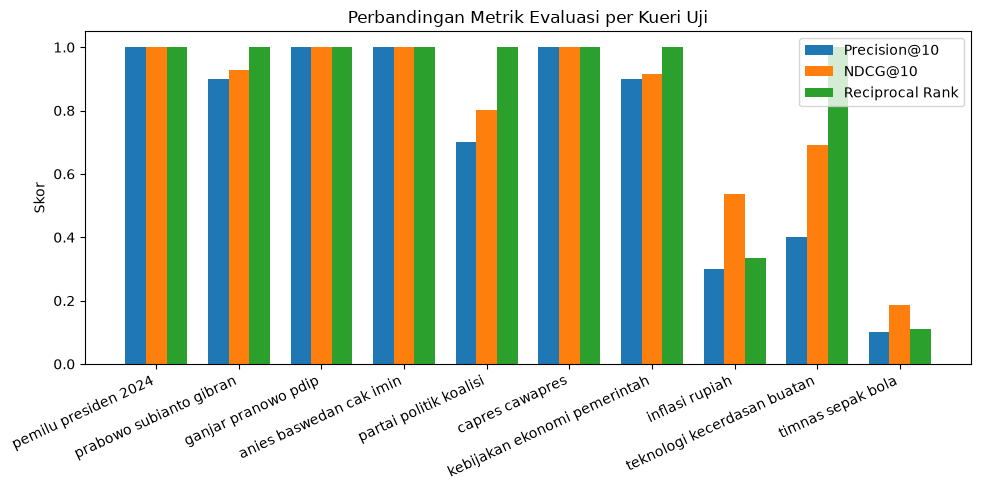

In [58]:
import matplotlib.pyplot as plt
import numpy as np

labels = eval_df["query"]
x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, eval_df["precision@10"], width, label="Precision@10")
ax.bar(x,         eval_df["ndcg@10"],      width, label="NDCG@10")
ax.bar(x + width, eval_df["reciprocal_rank"], width, label="Reciprocal Rank")

ax.set_ylabel("Skor")
ax.set_title("Perbandingan Metrik Evaluasi per Kueri Uji")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig("../data/evaluasi_per_query.png", dpi=150)
plt.show()

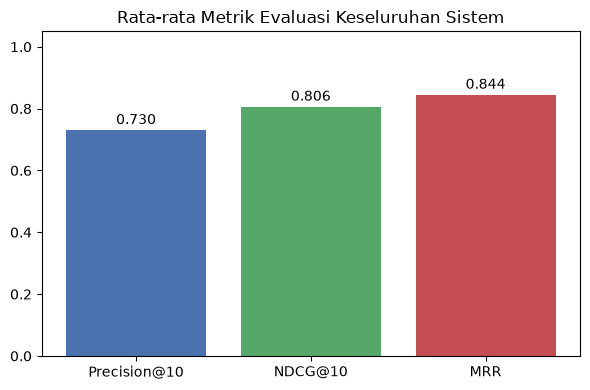

In [59]:
avg_metrics = {
    "Precision@10": mean_precision,
    "NDCG@10": mean_ndcg,
    "MRR": mean_rr,
}

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(avg_metrics.keys(), avg_metrics.values(), color=["#4C72B0", "#55A868", "#C44E52"])

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.02, f"{height:.3f}", ha="center")

ax.set_ylim(0, 1.05)
ax.set_title("Rata-rata Metrik Evaluasi Keseluruhan Sistem")
plt.tight_layout()
plt.savefig("../data/evaluasi_rata_rata.png", dpi=150)
plt.show()

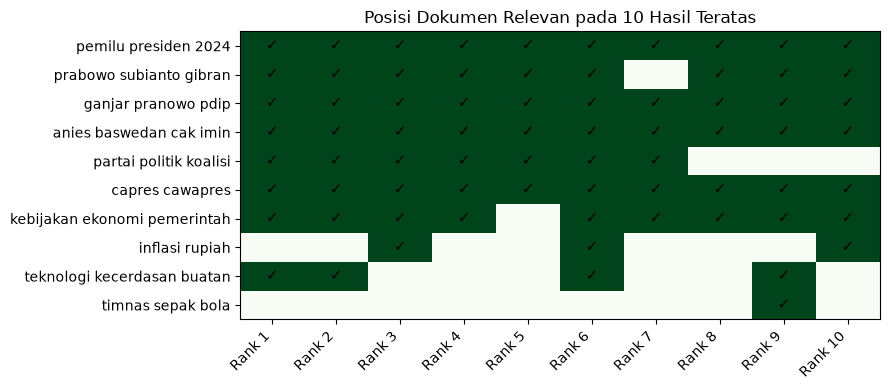

In [60]:
queries = list(relevance_patterns.keys())
matrix = np.array([relevance_patterns[q] for q in queries])

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(matrix, cmap="Greens", aspect="auto", vmin=0, vmax=1)

ax.set_xticks(range(K))
ax.set_xticklabels([f"Rank {i+1}" for i in range(K)], rotation=45, ha="right")
ax.set_yticks(range(len(queries)))
ax.set_yticklabels(queries)
ax.set_title("Posisi Dokumen Relevan pada 10 Hasil Teratas")

# Tambahkan tanda centang/silang di tiap kotak
for i in range(len(queries)):
    for j in range(K):
        symbol = "✓" if matrix[i, j] == 1 else ""
        ax.text(j, i, symbol, ha="center", va="center", color="black", fontsize=11)

plt.tight_layout()
plt.savefig("../data/heatmap_posisi_relevansi.png", dpi=150)
plt.show()